# Data Analysis | Correlates of War

# Introduction
In this notebook, we will perform a data analysis on our dataset. Let us remember our question:

- Is the distance between city capitals and Moscow, the capital of Russia, a value correlated with **higher defense expenditures**, measured as % of GDP?

## Motivation
Given our problem, we can do a **comparative** analysis and uncover possible **correlations** between **% GDP expenditures on defense** and **distance between European capitals and Moscow** (capital of Russia).

## Expected outcomes
After working through this problem, we want to:
- Define our `y` and `x` variables and identify them in the data.
- Use this study case to understand concepts of conditional probability, conditional distribution, and conditional mean.
- Create informative visualizations to understand conditional means, other conditional statistics, and joint distributions of quantitative variables.
- Understand the concepts of dependence, mean-dependence, and correlation, and produce and interpret correlation coefficients.

# Set up libraries and working environment, import dataset


In [123]:
# Import required libraries
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.ticker as mticker


In [124]:
# Create directory folders to store our data
dirname = os.getcwd()

raw_data = f"{dirname}/data/raw/"
transformed_data = f"{dirname}/data/transformed/"
refined_data = f"{dirname}/data/refined/"

paths = [raw_data, transformed_data, refined_data]

for path in paths:
    if not os.path.exists(path):
        os.makedirs(path)
    

In [125]:
# Import data
eur_military_expenditures = pd.read_csv(f"{transformed_data}military_expenditures_final.csv")

In [126]:
eur_military_expenditures.shape

(1364, 13)

In [127]:
eur_military_expenditures.head()

,country,year,military_expenditures_usd_2022,military_expenditures_current_usd,share_GDP,share_govt,capital_city,latitude,longitude,moscow_lat,moscow_long,distance_km,distance_mi
0,Albania,1993,1.515335e+08,3.928984e+07,0.031995,NaN,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.95987
1,Albania,1994,1.448474e+08,4.964950e+07,0.025478,NaN,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.95987
2,Albania,1995,1.349759e+08,5.090752e+07,0.020536,NaN,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.95987
3,Albania,1996,1.212103e+08,4.571336e+07,0.013790,NaN,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.95987
4,Albania,1997,8.462970e+07,2.982549e+07,0.012831,0.044247,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.95987


In [128]:
eur_military_expenditures.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1364 entries, 0 to 1363
Data columns (total 13 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   country                            1364 non-null   object 
 1   year                               1364 non-null   int64  
 2   military_expenditures_usd_2022     1318 non-null   float64
 3   military_expenditures_current_usd  1318 non-null   float64
 4   share_GDP                          1287 non-null   float64
 5   share_govt                         1187 non-null   float64
 6   capital_city                       1364 non-null   object 
 7   latitude                           1364 non-null   float64
 8   longitude                          1364 non-null   float64
 9   moscow_lat                         1364 non-null   float64
 10  moscow_long                        1364 non-null   float64
 11  distance_km                        1364 non-null   float

## Sample selection
Let's work with the latest year of data.

In [129]:
eur_military_expenditures_2023 = eur_military_expenditures.loc[
    lambda x: (eur_military_expenditures["year"] == 2023)
]

In [130]:
eur_military_expenditures_2023.describe()

,year,military_expenditures_usd_2022,military_expenditures_current_usd,share_GDP,share_govt,latitude,longitude,moscow_lat,moscow_long,distance_km,distance_mi
count,44.0,4.400000e+01,4.400000e+01,43.000000,42.000000,44.000000,44.000000,4.400000e+01,4.400000e+01,44.000000,44.000000
mean,2023.0,1.323713e+10,1.368996e+10,0.027675,0.072746,48.243806,17.583793,5.575500e+01,3.762180e+01,1825.976727,1134.609336
std,0.0,2.514649e+10,2.445075e+10,0.054203,0.113470,6.950434,14.066383,1.437515e-14,7.187574e-15,757.181172,470.490568
min,2023.0,0.000000e+00,0.000000e+00,0.002169,0.010164,35.899700,-21.895400,5.575500e+01,3.762180e+01,0.000000,0.000000
25%,2023.0,9.002800e+08,1.010842e+09,0.014880,0.030662,42.330825,12.047350,5.575500e+01,3.762180e+01,1549.842711,963.027613
50%,2023.0,3.556465e+09,3.892429e+09,0.016811,0.040611,47.823100,18.698150,5.575500e+01,3.762180e+01,1799.813883,1118.352499
75%,2023.0,8.716312e+09,8.690143e+09,0.022662,0.056286,52.726575,24.800175,5.575500e+01,3.762180e+01,2219.446176,1379.099917
max,2023.0,1.264734e+11,1.094544e+11,0.366531,0.581707,64.135500,49.892000,5.575500e+01,3.762180e+01,3915.117069,2432.740961


# Visualize the distribution of `share_GDP`
Let's take a look at the distribution of `share_GDP`.

In [131]:
eur_military_expenditures_2023.loc[:, ["share_GDP"]].describe()

,share_GDP
count,43.000000
mean,0.027675
std,0.054203
min,0.002169
25%,0.014880
50%,0.016811
75%,0.022662
max,0.366531


We can say a few things about it:
- The average expenditure as a percentage of GDP is 2.7%.
- The standard deviation is quite high (5.7%), so we can expect some skewness.
- The median is 1.6%, which confirms the previous assumption.
- The highest value is an astonishing 36%, which is probably due to Ukraine.

We should remove Ukraine from this dataset, as it will influence our data and we are interested on the other countries that are not in war with Russia.


In [132]:
eur_df_2023_no_ukr = eur_military_expenditures_2023.loc[
    (lambda x: eur_military_expenditures_2023["country"] != "Ukraine")
].copy()

Let's profile our data once again.

In [133]:
eur_df_2023_no_ukr.loc[:, ["share_GDP"]].describe()

,share_GDP
count,42.000000
mean,0.019607
std,0.011933
min,0.002169
25%,0.014807
50%,0.016577
75%,0.022306
max,0.058642


Aha! As we can see, our values changed quite a bit.
- The mean value is 1.9%, while the standard deviation is "just" 1.1%.
- Our median value is 1.6%, which suggests some skewness.

Let's visualize this distribution.

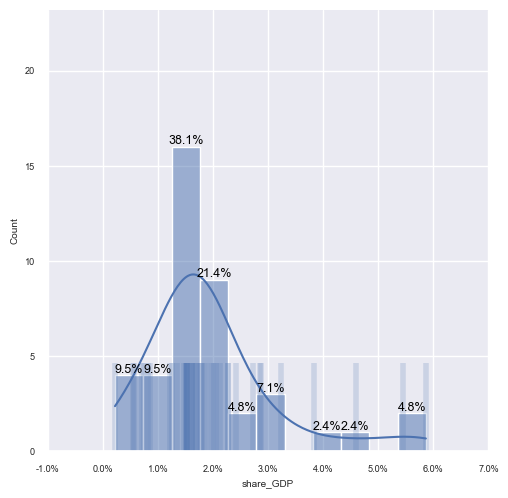

In [134]:
sns.set_style("darkgrid")
sns.set_theme(font_scale=0.6)
ax = sns.displot(
    data=eur_df_2023_no_ukr["share_GDP"], 
    binwidth=0.005,
    kde=True, 
    rug=True,
    rug_kws={"alpha": 0.2, "linewidth": 4, "height": 0.2})
ax.set_xticklabels(ha="center")
for x in ax.axes.flat:
    x.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x*100:.1f}%"))
    total = sum(p.get_height() for p in x.patches)
    # Annotate bars
    for patch in x.patches:
        height = patch.get_height()
        if height > 0:
            percent = 100 * height / total
            x.annotate(
                f"{percent:.1f}%",
                (patch.get_x() + patch.get_width() / 2, height),
                ha="center", va="bottom", fontsize=9, color="black"
            )

plt.show()

As we can see, most countries allocate between 1.5 and 2.0% of their GDP to the military sector. This is, by far, our **mode**.

Let us now check the distribution of the distance from Moscow.

In [135]:
eur_df_2023_no_ukr.loc[:, ["distance_km"]].describe()

,distance_km
count,43.000000
mean,1850.817208
std,747.781568
min,0.000000
25%,1569.586800
50%,1804.240314
75%,2224.437012
max,3915.117069


Let's take a look at the summary statistics:
- The average distance is 1850km.
- The standard deviation is 747km.
- The median is 1805, which hints at a more normal distribution.
- The highest value is 3915km.

Let's visualize the data.


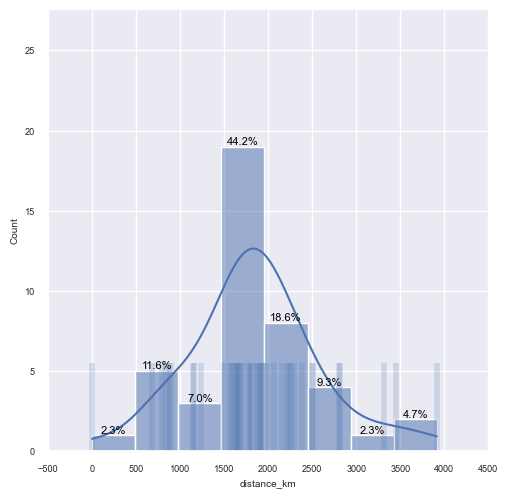

In [136]:
sns.set_style("darkgrid")
sns.set_theme(font_scale=0.6)
ax = sns.displot(
    data=eur_df_2023_no_ukr["distance_km"], 
    binwidth=500,
    kde=True, 
    rug=True,
    rug_kws={"alpha": 0.2, "linewidth": 4, "height": 0.2})
ax.set_xticklabels(ha="center")
for x in ax.axes.flat:
    # Set number of ticks
    x.xaxis.set_major_locator(mticker.MaxNLocator())
    total = sum(p.get_height() for p in x.patches)
    # Annotate bars
    for patch in x.patches:
        height = patch.get_height()
        if height > 0:
            percent = 100 * height / total
            x.annotate(
                f"{percent:.1f}%",
                (patch.get_x() + patch.get_width() / 2, height),
                ha="center", va="bottom", fontsize=8, color="black"
            )

plt.show()

As we can see, most countries are at a distance between 1500 and 2000km, roughly.
# Conditional probabilty | Binning distance from Moscow and visualize the GDP expenditures
Because both variables are **quantitative**, we need to create a **qualitative** variable by binning `distance_km` using three different categories: **close**, **medium**, and **far** from Moscow. 

Remember that the conditional probability of an event means the probabiluty of an event if another event (the conditional event) happens. In our case, we want to measure the probability of an increase in `share_GDP` if a country's capital is closer to Moscow (`distance_km`).

Let us then create three bins and label them as `Close`, `Medium`, and `Far`.



In [137]:
distance_bins = [1, 2, 3]
distance_labels = ["Close", "Medium", "Far"]

eur_df_2023_no_ukr["distance_bins"] = pd.cut(
    eur_df_2023_no_ukr["distance_km"],
    bins=3,
    labels=False,
    include_lowest=True
) + 1

bin_label_map = dict(zip(distance_bins, distance_labels))
eur_df_2023_no_ukr["distance_km_category"] = eur_df_2023_no_ukr["distance_bins"].map(bin_label_map)

In [138]:
eur_df_2023_no_ukr.head()

,country,year,military_expenditures_usd_2022,military_expenditures_current_usd,share_GDP,share_govt,capital_city,latitude,longitude,moscow_lat,moscow_long,distance_km,distance_mi,distance_bins,distance_km_category
30,Albania,2023,3.399298e+08,3.976176e+08,0.017440,0.056195,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.959870,2,Medium
61,Armenia,2023,1.152829e+09,1.329533e+09,0.054509,0.199607,Yerevan,40.1820,44.5146,55.755,37.6218,1804.240314,1121.102955,2,Medium
92,Austria,2023,3.981109e+09,4.409985e+09,0.008443,0.016326,Vienna,48.2064,16.3707,55.755,37.6218,1674.501261,1040.486845,2,Medium
123,Azerbaijan,2023,3.228238e+09,3.561671e+09,0.046021,0.147062,Baku,40.3777,49.8920,55.755,37.6218,1932.401811,1200.738817,2,Medium
154,Belarus,2023,1.248816e+09,1.403134e+09,0.017977,0.505913,Minsk,53.9000,27.5667,55.755,37.6218,677.698516,421.102335,1,Close


Also, because we have many different values for `share_GDP`, we could bin our values using our median as the reference. Remember that our median value is `0.016`. As a threshold value for high expenditures, we could use NATO's 2% benchmark value.

In [ ]:
share_gdp_bins = [
    eur_df_2023_no_ukr["share_GDP"].min(), 
    eur_df_2023_no_ukr["share_GDP"].median(),
    0.02, # 2% threhsold
    eur_df_2023_no_ukr["share_GDP"].max()]

In [143]:
eur_df_2023_no_ukr["share_gdp_bins"] = pd.cut(
    eur_df_2023_no_ukr["share_GDP"],
    bins=share_gdp_bins, 
    labels=False,
    include_lowest=True) + 1

share_gdp_labels = ["< 1.6%", "1.6 - 2.0%", "> 2%"]
bin_label_map = dict(zip([1, 2, 3], share_gdp_labels))
eur_df_2023_no_ukr["share_gdp_label"] = eur_df_2023_no_ukr["share_gdp_bins"].map(bin_label_map)

In [144]:
bin_label_map

{1: '< 1.6%', 2: '1.6 - 2.0%', 3: '> 2%'}

In [145]:
eur_df_2023_no_ukr.head()

,country,year,military_expenditures_usd_2022,military_expenditures_current_usd,share_GDP,share_govt,capital_city,latitude,longitude,moscow_lat,moscow_long,distance_km,distance_mi,distance_bins,distance_km_category,share_gdp_bins,share_gdp_label
30,Albania,2023,3.399298e+08,3.976176e+08,0.017440,0.056195,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.959870,2,Medium,2.0,1.6 - 2.0%
61,Armenia,2023,1.152829e+09,1.329533e+09,0.054509,0.199607,Yerevan,40.1820,44.5146,55.755,37.6218,1804.240314,1121.102955,2,Medium,3.0,> 2%
92,Austria,2023,3.981109e+09,4.409985e+09,0.008443,0.016326,Vienna,48.2064,16.3707,55.755,37.6218,1674.501261,1040.486845,2,Medium,1.0,< 1.6%
123,Azerbaijan,2023,3.228238e+09,3.561671e+09,0.046021,0.147062,Baku,40.3777,49.8920,55.755,37.6218,1932.401811,1200.738817,2,Medium,3.0,> 2%
154,Belarus,2023,1.248816e+09,1.403134e+09,0.017977,0.505913,Minsk,53.9000,27.5667,55.755,37.6218,677.698516,421.102335,1,Close,2.0,1.6 - 2.0%


## Plotting stacked charts - Describing patterns of association
Let's visualize conditional probabilities. Our goal is to visualize the proportion that each of the three binned categories represent for each distance category.

In [87]:
eur_df_2023_no_ukr.head()

,country,year,military_expenditures_usd_2022,military_expenditures_current_usd,share_GDP,share_govt,capital_city,latitude,longitude,moscow_lat,moscow_long,distance_km,distance_mi,distance_bins,distance_km_category,share_GDP_bin
30,Albania,2023,3.399298e+08,3.976176e+08,0.017440,0.056195,Tirana,41.3275,19.8189,55.755,37.6218,2061.505081,1280.959870,2,Medium,2
61,Armenia,2023,1.152829e+09,1.329533e+09,0.054509,0.199607,Yerevan,40.1820,44.5146,55.755,37.6218,1804.240314,1121.102955,2,Medium,3
92,Austria,2023,3.981109e+09,4.409985e+09,0.008443,0.016326,Vienna,48.2064,16.3707,55.755,37.6218,1674.501261,1040.486845,2,Medium,1
123,Azerbaijan,2023,3.228238e+09,3.561671e+09,0.046021,0.147062,Baku,40.3777,49.8920,55.755,37.6218,1932.401811,1200.738817,2,Medium,3
154,Belarus,2023,1.248816e+09,1.403134e+09,0.017977,0.505913,Minsk,53.9000,27.5667,55.755,37.6218,677.698516,421.102335,1,Close,2


In [146]:
df_stacked = pd.DataFrame(
    eur_df_2023_no_ukr.loc[:, ["distance_bins", "share_gdp_bins"]].groupby(["distance_bins", "share_gdp_bins"], observed=True).agg("size")
).reset_index()

df_stacked.columns  = ["distance_bins", "share_gdp_bins","count"]

group_counts = df_stacked.groupby("distance_bins", observed=True).agg("sum")["count"]


df_stacked.loc[df_stacked["distance_bins"] == 1, "percent"] = round(df_stacked.loc[df_stacked["distance_bins"] == 1, "count"]/group_counts[1],5)
df_stacked.loc[df_stacked["distance_bins"] == 2, "percent"] = round(df_stacked.loc[df_stacked["distance_bins"] == 2, "count"]/group_counts[2],5)
df_stacked.loc[df_stacked["distance_bins"] == 3, "percent"] = round(df_stacked.loc[df_stacked["distance_bins"] == 3, "count"]/group_counts[3],5)



In [147]:
df_stacked

,distance_bins,share_gdp_bins,count,percent
0,1,1.0,2,0.22222
1,1,2.0,1,0.11111
2,1,3.0,6,0.66667
3,2,1.0,15,0.51724
4,2,2.0,6,0.20690
5,2,3.0,8,0.27586
6,3,1.0,4,1.00000


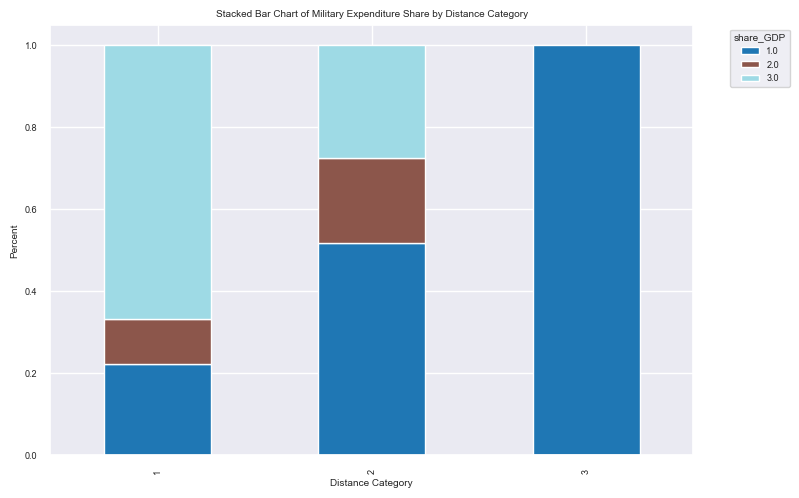

In [149]:
# Pivot the DataFrame to have share_GDP as columns, distance_category as index, and percent as values
pivot_df = df_stacked.pivot(index="distance_bins", columns="share_gdp_bins", values="percent").fillna(0)

# Plot the stacked bar chart
pivot_df.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    colormap='tab20'
)

plt.ylabel("Percent")
plt.xlabel("Distance Category")
plt.title("Stacked Bar Chart of Military Expenditure Share by Distance Category")
plt.legend(title="share_GDP", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()